# Frozen PANNs: Does the Training-Noise Distribution Matter?

This study compares **clean**, **Gaussian-adapted**, and **recorded-background-adapted** linear classifiers on the same frozen PANNs representation. The new intervention changes the training interference distribution; it does not add attention, another nonlinear classifier, or encoder training.

The notebook reads the completed Colab experiment and computes its tables, figures, and conclusions from saved predictions. It reports the whole fixed SNR grid and all evaluation recordings, including unfavorable results.

**Primary question:** Does recorded-background exposure improve designated-foreground classification relative to Gaussian exposure on the reserved recorded-background panel?
**Observed result:** recorded-background exposure improves the reserved recorded grid by **+1.36 pp [0.41, 2.32]**, while Gaussian-10-dB accuracy is **10.30 pp lower** than the Gaussian-trained head. Clean accuracy differs by −0.25 pp with an interval spanning zero. This is a distribution-dependent tradeoff.


## Context and methods

The foreground training population contains **1,200 ESC-50 clips**; development contains **398 clips from 295 original recording sources**. These target clips have historical exposure. The new holdout concerns background-recording identities, not new foreground examples.

All three systems use the same frozen `Cnn14_16k` encoder, 2,048-dimensional features, clean-training scaler, and 50-class multinomial logistic-regression family. The recorded-adapted head uses the saved Gaussian experiment's exact per-target SNR assignments and weights: clean weight 0.5 and two augmented variants of weight 0.25 each, for total weight 1,200. The solver, regularization, and convergence settings are fixed. The existing clean and Gaussian heads are reused.

For each fixed recorded condition, every target is mixed with the same designated background segment using full-window target power and mean-centered noise, without clipping. Background events may themselves belong to ESC-50 categories. The task predicts the **designated foreground label**, rather than detecting every event in a polyphonic scene.

The primary contrast averages the recorded-minus-Gaussian correctness difference equally over the fixed background/segment/SNR conditions within each clip, then across clips. The 95% interval resamples original foreground recording sources, retaining their clips. It is conditional on the fitted heads, augmentation draw, selected background recordings, segments, and SNR grid. It does not estimate uncertainty over future acoustic environments.

For a waveform $x\in\mathbb{R}^{80000}$, the frozen encoder returns $f_\theta(x)\in\mathbb{R}^{2048}$. Clean-training means and scales standardize this vector; $W\in\mathbb{R}^{50\times2048}$ and $b\in\mathbb{R}^{50}$ produce the softmax class scores. Only $W,b$ are fitted. With $z_i^0,z_i^A,z_i^B$ denoting standardized clean and augmented features, the adapted objective is

$$\frac1{1200}\sum_{i=1}^{1200}\left[0.5\ell(Wz_i^0+b,y_i)+0.25\ell(Wz_i^A+b,y_i)+0.25\ell(Wz_i^B+b,y_i)\right]+\frac{\lVert W\rVert_F^2}{2C\cdot1200},\quad C=1.$$

The weights sum to one per original target. Keeping their total fixed preserves the effective regularization; simply tripling unweighted rows would change it. Noise is mixed **before** the nonlinear encoder, so $f_\theta(x+\alpha n)$ is not replaced by $f_\theta(x)+\alpha f_\theta(n)$. The encoder receives the actual mixture.


## Locate the project

Saved-evidence analysis is the default. To run missing model computation, provide the official assets and cached clean embeddings described by the project, set `RUN_EXPERIMENT=True`, and use a GPU runtime. Completed results are reused by the runner.
For an independent repetition, use the runner with a fresh output directory; the completed report directory is retained and reused.


In [ ]:
from pathlib import Path
import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_EXPERIMENT = False
candidates = [Path(os.environ.get("ESC50_PROJECT_ROOT", ".")), Path.cwd(), Path.cwd().parent, Path("/content/esc50_project")]
ROOT = next((p.resolve() for p in candidates if (p/"src/esc50_sound").is_dir()), None)
if ROOT is None:
    ROOT = Path("/content/esc50_project")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Richardafcs/esc-50-sound-classification.git", str(ROOT)], check=True)
DATA = ROOT/"reports/noise_distribution_20261107"
ASSETS = Path("/content/esc50_noise_assets")
if RUN_EXPERIMENT:
    subprocess.run([sys.executable, str(ROOT/"scripts/run_noise_distribution.py"),
                    "--assets", str(ASSETS), "--output", str(DATA),
                    "--protocol", str(DATA/"protocol.json"), "--device", "cuda"], check=True)
print("Mode:", "Repeat fixed experiment" if RUN_EXPERIMENT else "Analyze completed evidence")
plt.rcParams.update({"figure.dpi":120,"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
COLORS={"clean_refit":"#28668e","gaussian_adapted":"#c87527","recorded_adapted":"#318268"}
LABELS={"clean_refit":"Clean-trained","gaussian_adapted":"Gaussian-adapted","recorded_adapted":"Recorded-adapted"}
MODELS=list(LABELS)

Mode: Analyze completed evidence


## Data and fixed protocol

The recording identities, SNR grid, mixture rule and primary weighting were specified before the new fit and predictions. The tables below expose their realized implementation. Multiple target/condition pairs share foreground and background recordings; their row count is not an independent-sample count.

In [ ]:
summary = json.loads((DATA/"summary.json").read_text())
protocol = json.loads((DATA/"protocol.json").read_text())
metrics = pd.read_csv(DATA/"metrics.csv")
aggregate = pd.read_csv(DATA/"aggregate_metrics.csv")
effects = pd.read_csv(DATA/"paired_effects.csv")
exposure = pd.read_csv(DATA/"training_exposure.csv")
backgrounds = pd.read_csv(DATA/"background_segments.csv")
conditions = pd.read_csv(DATA/"conditions.csv")
recorded = metrics[metrics.environment.fillna("").ne("") & metrics.environment.ne("Gaussian")].copy()
snr_grid = sorted(recorded.snr_db.unique())
evaluation_environments = sorted(recorded.environment.unique())
display(Markdown("### Execution evidence"))
display(pd.DataFrame([{
    "Foreground train clips":summary["train_clips"], "Development clips":summary["development_clips"],
    "Development sources":summary["development_sources"], "New head fits":summary["new_head_fits"],
    "Encoder fits":summary["encoder_fits"], "Recorded conditions":summary["recorded_conditions"],
    "Target/condition pairs":summary["target_noise_pairs"], "Test WAVs read":summary["test_waveforms_read"]
}]).T.rename(columns={0:"Value"}))
print("Compute time:", round(summary["compute_seconds"],2), "seconds; setup and downloads excluded.")
print("Execution environment:", summary["environment"])
display(pd.DataFrame([summary["fit"]]).round(4))
display(Markdown("### Frozen protocol"))
display(pd.DataFrame({
    "Category":["Domestic","Nature","Office","Public","Street","Transport"],
    "Training recording":protocol["training"]["backgrounds"],
    "Evaluation recording":protocol["evaluation"]["backgrounds"]
}))
print("Evaluation start times (s):",protocol["evaluation"]["start_seconds"],"; SNR grid (dB):",protocol["evaluation"]["snr_db_grid"])
print("Training source/crop seeds:",protocol["training"]["seed"],protocol["training"]["crop_seed"])
display(Markdown("Full machine-readable settings: [protocol.json](../reports/noise_distribution_20261107/protocol.json). All 36 recorded conditions are retained."))

### Execution evidence

,Value
Foreground train clips,1200
Development clips,398
Development sources,295
New head fits,1
Encoder fits,0
Recorded conditions,36
Target/condition pairs,14328
Test WAVs read,0


Compute time: 243.48 seconds; setup and downloads excluded.
Execution environment: {'python': '3.13.16', 'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'scikit_learn': '1.6.1', 'gpu': 'Tesla T4'}


,model,rows,total_weight,iterations,converged,seconds,feature_dtype,transformed_dtype
0,recorded_adapted,3600,1200.0,169,True,26.1205,float32,float32


### Frozen protocol

,Category,Training recording,Evaluation recording
0,Domestic,DKITCHEN,DLIVING
1,Nature,NFIELD,NPARK
2,Office,OMEETING,OOFFICE
3,Public,PRESTO,PCAFETER
4,Street,SPSQUARE,STRAFFIC
5,Transport,TBUS,TMETRO


Evaluation start times (s): [60, 210] ; SNR grid (dB): [0, 10, 20]
Training source/crop seeds: 20261107 20261108


Full machine-readable settings: [protocol.json](../reports/noise_distribution_20261107/protocol.json). All 36 recorded conditions are retained.

In [ ]:
display(Markdown("### Training exposure and background signal measurements"))
display(exposure.groupby(["variant","environment"],as_index=False).agg(
    augmented_rows=("filename","size"),total_augmented_weight=("weight","sum"),
    minimum_snr_db=("snr_db","min"),maximum_snr_db=("snr_db","max")
).round(3))
display(backgrounds.round(3))
display(Markdown("Signal descriptors characterize the selected segments; they do not establish an acoustic cause of classification errors or guarantee that the foreground label remains perceptually dominant."))
print("Realized training SNR range:", round(exposure.realized_snr_db.min(),5), "to", round(exposure.realized_snr_db.max(),5), "dB")

### Training exposure and background signal measurements

,variant,environment,augmented_rows,total_augmented_weight,minimum_snr_db,maximum_snr_db
0,0,DKITCHEN,200,50.0,10.018,29.919
1,0,NFIELD,200,50.0,10.157,30.000
2,0,OMEETING,200,50.0,10.348,29.856
3,0,PRESTO,200,50.0,10.032,29.928
4,0,SPSQUARE,200,50.0,10.246,29.984
5,0,TBUS,200,50.0,10.067,29.884
6,1,DKITCHEN,200,50.0,10.225,29.794
7,1,NFIELD,200,50.0,10.036,29.903
8,1,OMEETING,200,50.0,10.071,29.967
9,1,PRESTO,200,50.0,10.055,29.996


,environment,role,channel,start_seconds,end_seconds,rms,peak,below_500hz_power_fraction,above_4000hz_power_fraction,spectral_centroid_hz
0,DLIVING,evaluation,ch01,60.0,65.0,0.001,0.006,0.912,0.004,146.218
1,DLIVING,evaluation,ch01,210.0,215.0,0.001,0.005,0.977,0.002,103.922
2,NPARK,evaluation,ch01,60.0,65.0,0.002,0.010,0.932,0.011,187.904
3,NPARK,evaluation,ch01,210.0,215.0,0.001,0.018,0.613,0.035,732.842
4,OOFFICE,evaluation,ch01,60.0,65.0,0.005,0.016,0.998,0.000,17.902
5,OOFFICE,evaluation,ch01,210.0,215.0,0.004,0.016,0.994,0.002,35.151
6,PCAFETER,evaluation,ch01,60.0,65.0,0.005,0.023,0.861,0.008,272.629
7,PCAFETER,evaluation,ch01,210.0,215.0,0.005,0.023,0.823,0.007,312.427
8,STRAFFIC,evaluation,ch01,60.0,65.0,0.011,0.045,0.936,0.006,178.814
9,STRAFFIC,evaluation,ch01,210.0,215.0,0.017,0.090,0.953,0.006,160.308


Signal descriptors characterize the selected segments; they do not establish an acoustic cause of classification errors or guarantee that the foreground label remains perceptually dominant.

Realized training SNR range: 10.01827 to 29.99962 dB


## Results

### Primary comparison and clean performance

Accuracy and macro-F1 use all 50 outputs. Recorded-grid summaries are equal-weight means of per-condition metrics. In particular, mean per-condition macro-F1 is not macro-F1 recomputed after pooling repeated targets.

In [ ]:
primary = effects[(effects.group=="recorded_grid_primary") & (effects.comparator=="gaussian_adapted")].iloc[0]
clean_effect = effects[(effects.group=="clean") & (effects.comparator=="gaussian_adapted")].iloc[0]
show_groups=["clean","historical_shared_gaussian10","recorded_grid_primary"]
result_table=aggregate[aggregate.group.isin(show_groups)].copy()
result_table["model"]=result_table.model.map(LABELS)
result_table["accuracy"]=100*result_table.accuracy
result_table["macro_f1"]=100*result_table.macro_f1
display(result_table.rename(columns={"accuracy":"Accuracy (%)","macro_f1":"Mean per-condition macro-F1 (%)","nll":"Mean NLL"}).round(3))
display(Markdown(f"**Primary recorded-minus-Gaussian change: {primary.delta_pp:+.2f} percentage points**, with conditional 95% target-source bootstrap interval **[{primary.low_pp:+.2f}, {primary.high_pp:+.2f}]**. The clean-input change between these heads is **{clean_effect.delta_pp:+.2f} pp**, with interval **[{clean_effect.low_pp:+.2f}, {clean_effect.high_pp:+.2f}]**."))
display(effects[effects.group=="recorded_grid_primary"][["comparator","delta_pp","low_pp","high_pp","conditions","clips","target_sources"]].round(3))

,model,group,conditions,Accuracy (%),Mean per-condition macro-F1 (%),Mean NLL
0,Clean-trained,recorded_grid_primary,36,82.880,83.115,0.791
1,Gaussian-adapted,recorded_grid_primary,36,83.431,83.784,0.772
2,Recorded-adapted,recorded_grid_primary,36,84.792,85.175,0.699
3,Clean-trained,clean,1,91.206,91.103,0.449
4,Gaussian-adapted,clean,1,91.960,91.961,0.465
5,Recorded-adapted,clean,1,91.709,91.431,0.464
6,Clean-trained,historical_shared_gaussian10,1,69.849,71.530,1.300
7,Gaussian-adapted,historical_shared_gaussian10,1,83.920,83.926,0.784
8,Recorded-adapted,historical_shared_gaussian10,1,73.618,74.603,1.114


**Primary recorded-minus-Gaussian change: +1.36 percentage points**, with conditional 95% target-source bootstrap interval **[+0.41, +2.32]**. The clean-input change between these heads is **-0.25 pp**, with interval **[-1.86, +1.45]**.

,comparator,delta_pp,low_pp,high_pp,conditions,clips,target_sources
0,gaussian_adapted,1.361,0.412,2.322,36,398,295
1,clean_refit,1.912,0.895,2.979,36,398,295


### Degradation curves across the complete SNR grid

Each point averages the fixed evaluation recordings and segments at that SNR. Lines connect predefined conditions; they do not imply that unmeasured SNRs were evaluated.

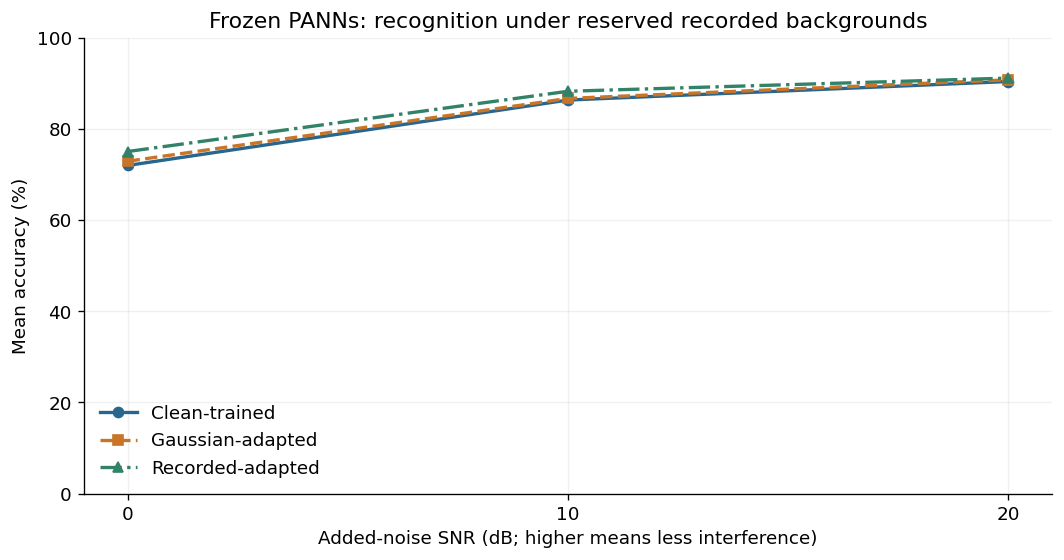

model,Clean-trained,Gaussian-adapted,Recorded-adapted
snr_db,,,
0.0,71.96,72.89,75.02
10.0,86.31,86.66,88.23
20.0,90.37,90.75,91.12


In [ ]:
curve=recorded.groupby(["model","snr_db"]).accuracy.mean().unstack("model").reindex(columns=MODELS)
fig,ax=plt.subplots(figsize=(9,4.8))
styles=[("o","-"),("s","--"),("^","-.")]
for model,(marker,line) in zip(MODELS,styles):
    ax.plot(curve.index,100*curve[model],marker=marker,linestyle=line,linewidth=2,
            color=COLORS[model],label=LABELS[model])
ax.set(xticks=snr_grid,ylim=(0,100),xlabel="Added-noise SNR (dB; higher means less interference)",
       ylabel="Mean accuracy (%)",title="Frozen PANNs: recognition under reserved recorded backgrounds")
ax.grid(alpha=.18);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(DATA/"snr_accuracy_curves.png",dpi=180,bbox_inches="tight");plt.show()
display((100*curve).rename(columns=LABELS).round(2))

### Does the mean hide different background responses?

Values below are **recorded-adapted minus Gaussian-adapted accuracy**, in percentage points, averaging the fixed segments of each recording. This is a descriptive breakdown of the primary panel, not a set of independent confirmations.

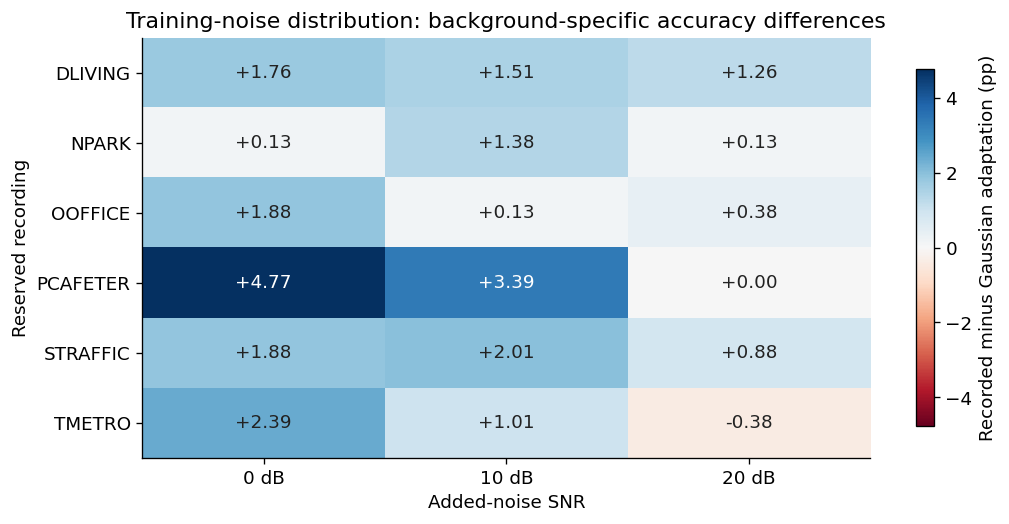

snr_db,0.0,10.0,20.0
environment,,,
DLIVING,1.76,1.51,1.26
NPARK,0.13,1.38,0.13
OOFFICE,1.88,0.13,0.38
PCAFETER,4.77,3.39,0.00
STRAFFIC,1.88,2.01,0.88
TMETRO,2.39,1.01,-0.38


In [ ]:
by_environment=recorded.groupby(["environment","snr_db","model"]).accuracy.mean().unstack("model")
change=(100*(by_environment.recorded_adapted-by_environment.gaussian_adapted)).unstack("snr_db").reindex(index=evaluation_environments,columns=snr_grid)
limit=max(1.,float(np.nanmax(np.abs(change.to_numpy()))))
fig,ax=plt.subplots(figsize=(9,max(3.7,.5*len(change)+1.5)))
image=ax.imshow(change.to_numpy(),cmap="RdBu",vmin=-limit,vmax=limit,aspect="auto")
for i in range(len(change)):
    for j in range(len(change.columns)):
        value=change.iloc[i,j]
        ax.text(j,i,f"{value:+.2f}",ha="center",va="center",color="white" if abs(value)>.58*limit else "#222222")
ax.set(xticks=np.arange(len(change.columns)),xticklabels=[f"{v:g} dB" for v in change.columns],
       yticks=np.arange(len(change)),yticklabels=change.index,xlabel="Added-noise SNR",ylabel="Reserved recording",
       title="Training-noise distribution: background-specific accuracy differences")
fig.colorbar(image,ax=ax,label="Recorded minus Gaussian adaptation (pp)",shrink=.85)
fig.tight_layout();fig.savefig(DATA/"environment_snr_effects.png",dpi=180,bbox_inches="tight");plt.show()
display(change.round(2))

### Paired effects and their uncertainty

The primary interval is the main inferential summary. Clean, Gaussian-control and SNR-specific intervals are secondary and unadjusted. All condition intervals share targets and are dependent. Neither these intervals nor leave-one-recording-out summaries quantify a population of future background environments.

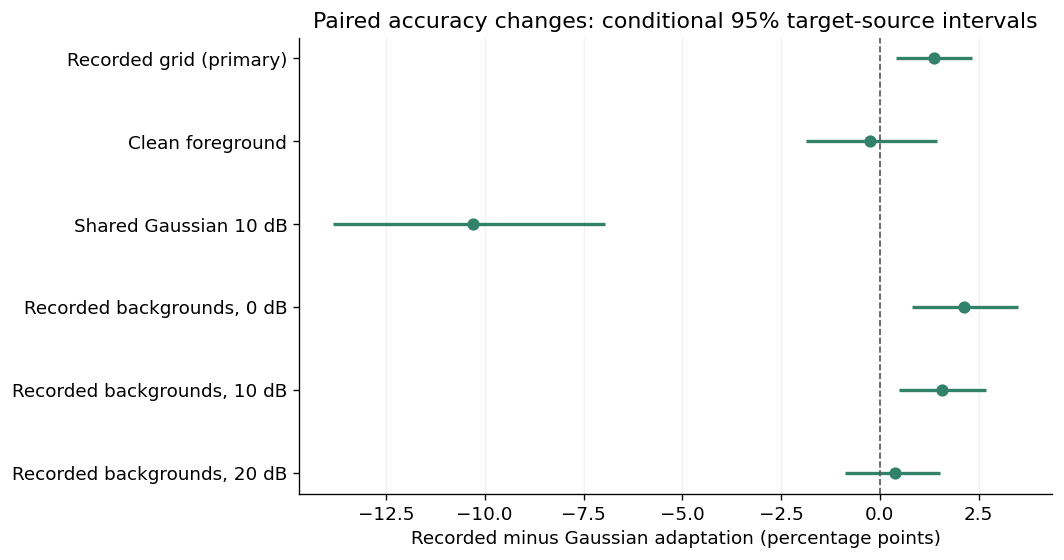

,delta_pp,low_pp,high_pp,conditions
group,,,,
recorded_grid_primary,1.361,0.412,2.322,36
clean,-0.251,-1.857,1.449,1
historical_shared_gaussian10,-10.302,-13.835,-6.948,1
snr_0,2.136,0.808,3.499,12
snr_10,1.570,0.481,2.695,12
snr_20,0.377,-0.880,1.515,12


### Leave-one-background-recording-out sensitivity

,group,delta_pp,low_pp,high_pp
14,leave_out_DLIVING,1.332,0.400,2.283
18,leave_out_NPARK,1.524,0.530,2.520
22,leave_out_OOFFICE,1.474,0.496,2.462
26,leave_out_PCAFETER,1.089,0.185,2.022
30,leave_out_STRAFFIC,1.315,0.339,2.296
34,leave_out_TMETRO,1.432,0.435,2.447


In [ ]:
selected=["recorded_grid_primary","clean","historical_shared_gaussian10"]+["snr_"+str(v) for v in protocol["evaluation"]["snr_db_grid"]]
forest=effects[effects.comparator.eq("gaussian_adapted")].set_index("group").loc[selected]
readable={"recorded_grid_primary":"Recorded grid (primary)","clean":"Clean foreground","historical_shared_gaussian10":"Shared Gaussian 10 dB"}
labels=[readable.get(g,f"Recorded backgrounds, {g.removeprefix('snr_')} dB") for g in selected]
y=np.arange(len(forest))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.hlines(y,forest.low_pp,forest.high_pp,color=COLORS["recorded_adapted"],linewidth=2)
ax.scatter(forest.delta_pp,y,color=COLORS["recorded_adapted"],s=40,zorder=3)
ax.axvline(0,color="#555555",linestyle="--",linewidth=1)
ax.set(yticks=y,yticklabels=labels,xlabel="Recorded minus Gaussian adaptation (percentage points)",
       title="Paired accuracy changes: conditional 95% target-source intervals")
ax.invert_yaxis();ax.grid(axis="x",alpha=.16)
fig.tight_layout();fig.savefig(DATA/"paired_distribution_effects.png",dpi=180,bbox_inches="tight");plt.show()
display(forest[["delta_pp","low_pp","high_pp","conditions"]].round(3))
display(Markdown("### Leave-one-background-recording-out sensitivity"))
display(effects[effects.group.str.startswith("leave_out_") & effects.comparator.eq("gaussian_adapted")][["group","delta_pp","low_pp","high_pp"]].round(3))

### Clean and noisy accuracy jointly

The three groups describe different operating conditions. Their visual comparison is not a pooled deployment score; the project has no specified real-world frequency for these conditions and no predefined acceptable clean-loss margin.

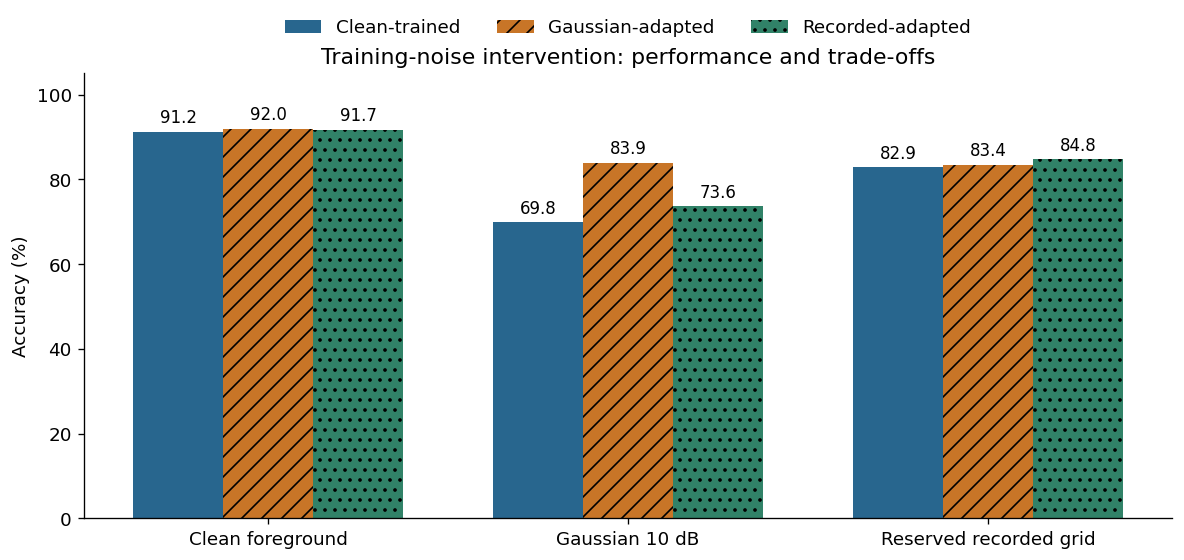

,model,group,Own-clean accuracy loss (pp)
0,clean_refit,recorded_grid_primary,8.326
1,gaussian_adapted,recorded_grid_primary,8.529
2,recorded_adapted,recorded_grid_primary,6.917
9,clean_refit,snr_0,19.242
10,gaussian_adapted,snr_0,19.075
11,recorded_adapted,snr_0,16.688
12,clean_refit,snr_10,4.899
13,gaussian_adapted,snr_10,5.297
14,recorded_adapted,snr_10,3.476
15,clean_refit,snr_20,0.838


In [ ]:
bar_groups=["clean","historical_shared_gaussian10","recorded_grid_primary"]
bar_labels=["Clean foreground","Gaussian 10 dB","Reserved recorded grid"]
bar_table=aggregate[aggregate.group.isin(bar_groups)].pivot(index="model",columns="group",values="accuracy").reindex(index=MODELS,columns=bar_groups)
fig,ax=plt.subplots(figsize=(10,4.8));x=np.arange(len(bar_groups));width=.25
for i,model in enumerate(MODELS):
    bars=ax.bar(x+(i-1)*width,100*bar_table.loc[model],width,color=COLORS[model],label=LABELS[model],hatch=["","//",".."][i])
    ax.bar_label(bars,fmt="%.1f",padding=3,fontsize=10)
ax.set(xticks=x,xticklabels=bar_labels,ylim=(0,105),ylabel="Accuracy (%)",title="Training-noise intervention: performance and trade-offs")
ax.legend(frameon=False,ncol=3,loc="upper center",bbox_to_anchor=(.5,1.16))
fig.tight_layout();fig.savefig(DATA/"clean_noise_tradeoffs.png",dpi=180,bbox_inches="tight");plt.show()
clean_accuracy=aggregate[aggregate.group=="clean"].set_index("model").accuracy
loss_rows=aggregate[aggregate.group.isin(["recorded_grid_primary"]+["snr_"+str(v) for v in protocol["evaluation"]["snr_db_grid"]])].copy()
loss_rows["Own-clean accuracy loss (pp)"]=100*(loss_rows.model.map(clean_accuracy)-loss_rows.accuracy)
display(loss_rows[["model","group","Own-clean accuracy loss (pp)"]].round(3))


### Exploratory errors by foreground class

The table lists the ten largest absolute class differences on the same fixed noise panel. Each class contains only about eight distinct foreground clips; repeated mixtures are not independent targets. These rows locate follow-up examples and do not identify acoustic mechanisms. The full 50-class table is retained as a CSV.

In [ ]:
predictions=pd.read_csv(DATA/"predictions.csv")
selected_predictions=predictions[predictions.environment.isin(evaluation_environments)].copy()
selected_predictions["correct"]=selected_predictions.prediction.eq(selected_predictions.target)
class_table=selected_predictions.groupby(["target","model"]).correct.mean().unstack("model").reindex(columns=MODELS)*100
class_table["Recorded minus Gaussian (pp)"]=class_table.recorded_adapted-class_table.gaussian_adapted
class_table["Distinct foreground clips"]=selected_predictions.groupby("target").filename.nunique()
class_table.to_csv(DATA/"per_class_recovery.csv")
display(class_table.loc[class_table["Recorded minus Gaussian (pp)"].abs().sort_values(ascending=False).head(10).index].round(2))
transitions=pd.read_csv(DATA/"transitions.csv")
recorded_condition_ids=conditions[conditions.environment.isin(evaluation_environments)].condition
display(transitions[transitions.condition.isin(recorded_condition_ids)].groupby("comparator")[["repairs","new_errors"]].sum().rename(columns={"repairs":"Paired mixture repairs","new_errors":"Paired mixture new errors"}))


model,clean_refit,gaussian_adapted,recorded_adapted,Recorded minus Gaussian (pp),Distinct foreground clips
target,,,,,
39,40.97,64.93,77.43,12.50,8
30,62.85,62.85,75.00,12.15,8
33,75.35,72.22,81.25,9.03,8
44,75.00,69.10,78.12,9.03,8
19,77.08,76.39,84.72,8.33,8
45,92.71,94.79,87.50,-7.29,8
12,84.38,86.81,79.86,-6.94,8
29,76.39,63.54,70.14,6.60,8
23,82.99,82.64,88.89,6.25,8


,Paired mixture repairs,Paired mixture new errors
comparator,,
clean_refit,519,245
gaussian_adapted,509,314


## Findings and scope

In [ ]:
if primary.low_pp>0:
    conclusion="Recorded-background exposure improves accuracy relative to Gaussian exposure on this fixed evaluation grid, with a positive conditional interval."
elif primary.high_pp<0:
    conclusion="Recorded-background exposure reduces accuracy relative to Gaussian exposure on this fixed evaluation grid. This intervention does not provide a beneficial replacement under the specified protocol."
else:
    conclusion="The recorded-versus-Gaussian difference remains uncertain under the conditional interval. This experiment does not establish an accuracy advantage."
display(Markdown(conclusion+f" The estimated difference is {primary.delta_pp:+.2f} pp. Clean performance changes by {clean_effect.delta_pp:+.2f} pp; this is not an equivalence or noninferiority result."))
display(Markdown("The intervention changes the complete training-noise distribution, including spectrum, temporal structure and semantic content. It does not isolate diversity alone. The result concerns fixed fitted heads and previously exposed foreground targets under reserved background recordings; it does not establish new-target generalization, representation invariance, auditory mechanisms or field deployment. No extra architecture, SNR policy or head was selected from these evaluation outcomes."))

Recorded-background exposure improves accuracy relative to Gaussian exposure on this fixed evaluation grid, with a positive conditional interval. The estimated difference is +1.36 pp. Clean performance changes by -0.25 pp; this is not an equivalence or noninferiority result.

The intervention changes the complete training-noise distribution, including spectrum, temporal structure and semantic content. It does not isolate diversity alone. The result concerns fixed fitted heads and previously exposed foreground targets under reserved background recordings; it does not establish new-target generalization, representation invariance, auditory mechanisms or field deployment. No extra architecture, SNR policy or head was selected from these evaluation outcomes.

## Primary sources and alternatives

The source review compares nearby work by actual task, split, objective and reading depth. Published benchmark scores use different experimental protocols and are not additional observations from this study.

In [ ]:
display(Markdown((DATA/"literature_review.md").read_text()))

# Literature Context for Training-Noise Distribution Transfer

Reviewed 7 November 2026. This review supports one controlled experiment, rather than a new architecture or a claim of algorithmic novelty. The question is whether recorded-background training improves a fixed PANNs linear classifier under interference from reserved background recordings, compared with clean and Gaussian training.

Reading depth is stated explicitly. Selected-section review means that the relevant methods, evaluation or results text was inspected; it does not mean that the complete implementation or every supplementary claim was independently reproduced. Published scores below describe their authors' protocols and are not directly comparable with this project's 398-clip development panel.

## Primary-source evidence matrix

| Source | Material inspected | Supported finding | Consequence and distinction for this study |
| --- | --- | --- | --- |
| McLoughlin et al., **Robust Sound Event Classification Using Deep Neural Networks** (2015), [institutional record](https://kar.kent.ac.uk/51341/) and [accepted manuscript](https://kar.kent.ac.uk/51341/1/machine_hearing.pdf) | Section IV-A, IV-B5, Table I, Section V-E and Table VIII. | RWCP experiments compare clean training with multi-condition training using three NOISEX-92 backgrounds, reserving speech babble for evaluation. Separately, Table I compares AWGN and NOISEX-92 corruption of a clean-trained SVM baseline. | This is close prior evidence for reserved-background robustness and clean/noisy trade-offs. It does **not** compare Gaussian-trained versus recorded-trained models. Our fixed-PANNs readout contrast remains a different controlled comparison, not the first demonstration of recorded-noise training or unseen-noise evaluation. |
| Salamon and Bello, **Deep Convolutional Neural Networks and Data Augmentation for Environmental Sound Classification** (2017), [paper](https://arxiv.org/html/1608.04363v2) | Sections II-B, II-C and III: augmentation, evaluation and class-level results. | Training includes mixtures with four recorded acoustic scenes, explicitly screened to exclude target sound classes. Mixture weights are sampled from 0.1–0.5. Evaluation uses UrbanSound8K ten-fold cross-validation, with a training fold reserved for validation. Effects differ across classes; background augmentation harms some classes. | Recorded-background augmentation is established. Our fixed representation, matched objective and reserved-background comparison answer a narrower transfer question. Unlike the authors' screened ten-class setting, our backgrounds may contain competing ESC-50 events. |
| Kong et al., **PANNs: Large-Scale Pretrained Audio Neural Networks for Audio Pattern Recognition** (2020), [paper](https://arxiv.org/html/1912.10211) | Section V and Section VI-D, particularly the ESC-50 transfer comparison and Table XIII. | The paper evaluates frozen embeddings with one- and three-layer classifiers and end-to-end fine-tuning. Its five-fold ESC-50 comparison reports 94.7% for fine-tuning. | Frozen-feature classification is an established transfer method. Fine-tuning is a plausible later intervention, but the clean benchmark result does not establish noise-transfer superiority. Table XIII and the following prose reverse the frozen-head ranking; this review therefore does not use that ranking. |
| Gong, Chung and Glass, **AST: Audio Spectrogram Transformer** (2021), [paper](https://arxiv.org/html/2104.01778v3) | Section 3.2, including training details and Table 7. | ESC-50 evaluation uses five folds, three repetitions, twenty training epochs and time/frequency masking. AST-S uses ImageNet pretraining; AST-P adds AudioSet pretraining. | AST-S is not a randomly initialized baseline. Published attention-model scores do not isolate attention from pretraining, optimization and architecture, nor demonstrate that adding attention will improve our particular noise-transfer result. |
| Chen et al., **BEATs: Audio Pre-Training with Acoustic Tokenizers** (2022/2023), [paper](https://arxiv.org/html/2212.09058) | Sections 4.1–4.5: datasets, comparison tables and disturbance visualization. | Uses five-fold ESC-50 accuracy and distinguishes supervised AudioSet exposure. Section 4.5 visualizes ten selected validation recordings under RIR and DNS-noise disturbances to examine pretraining-target representations. | The disturbance visualization is not a paired classification-accuracy experiment on held-out backgrounds. Strong benchmark performance motivates a possible later representation comparison; it does not settle whether our readout-level training intervention transfers. |
| Guzhov et al., **ESResNe(X)t-fbsp: Learning Robust Time-Frequency Transformation of Audio** (2021), [paper](https://arxiv.org/html/2104.11587) | Sections IV-D–E and V-C, with model-comparison context. | Compares learned frequency B-spline frontends with STFT frontends and evaluates Gaussian-noise degradation and low-pass perturbations. Authors relate Gaussian robustness to learned frequency responses. | Frontend choices can affect perturbation sensitivity, so our encoder/frontend must remain fixed when attributing differences to training exposure. This paper does not test our frozen-readout or reserved recorded-background intervention. |
| Thiemann, Ito and Vincent, **DEMAND** (2013), [official dataset](https://zenodo.org/records/1227121) | Official description, recording format, license and archive inventory. | Supplies environmental recordings captured with a sixteen-channel microphone array, available at 16 and 48 kHz. The stated license is CC BY-SA 3.0. | Channels are simultaneous measurements of a recording environment, not independent environments. Reserve complete recordings between training and evaluation. This corpus permits controlled interference experiments; it is not by itself a representative sample of deployment conditions. |
| Snyder, Chen and Povey, **MUSAN: A Music, Speech, and Noise Corpus** (2015), [paper](https://arxiv.org/html/1510.08484) | Corpus description, particularly Section 2.3. | The noise portion contains 929 files/about six hours, including technical and environmental sounds; some crowd recordings contain indistinct voices. Sources include Freesound and Sound Bible with different license provenance. | A file labelled noise can contain an ESC-50 target category. MUSAN is an alternative source of interference, not automatically label-neutral or independent of Freesound-derived targets. This experiment does not add it merely to increase dataset count. |
| Shao et al., **DHAuDS: A Dynamic and Heterogeneous Audio Benchmark for Test-Time Adaptation** (2025; revision June 2026), [paper](https://arxiv.org/html/2511.18421) | Sections 3–4: corruption settings, adaptation/evaluation separation and model definitions. | Combines heterogeneous noise sources and severity ranges, using different random seeds for adaptation and evaluation corruptions. Its task is test-time adaptation, rather than supervised fitting of a frozen-feature classifier. | Separate random draws do not establish background-source independence. Section 3.3.2 counts DEMAND channels as recordings; this review does not adopt that count as independent environmental replication. Severity variation is relevant, but our complete predefined grid answers a simpler fixed-head question. |
| Goulão et al., **Training Environmental Sound Classification Models for Real-World Deployment in Edge Devices** (2024), [paper](https://link.springer.com/article/10.1007/s42452-024-05803-7) | Sections 3–5 and 8–9: data, models, distillation, ESC-50 benchmarking and deployment discussion. | Separates five-fold ESC-50 benchmarking from a street-luminaire multilabel application. Real recordings differ in noise, class balance and annotation difficulty; some quiet classes remain problematic. Private deployment audio is unavailable publicly. | Useful evidence that benchmark accuracy and deployment performance are different measurements. Its multilabel street task, devices and labels differ from our designated-foreground classification. An additive-mixture gain cannot establish equivalent performance in that application or identify its failure mechanism. |
| Abeßer, Grollmisch and Müller, **How Robust Are Audio Embeddings for Polyphonic Sound Event Tagging?** (2023), [institutional record](https://cris.fau.de/publications/318625461/) and [official ESC50Mix dataset](https://zenodo.org/records/7913138) | Institutional abstract and official dataset description. Repository full-paper retrieval failed; detailed classifier/split settings were not verified. | Studies degradation-related embedding drift and trajectories from blending pairs of sounds. ESC50Mix describes 1,000 pairs, six gain factors and five augmentation conditions, producing 30,000 five-second mixtures. | Directly relevant to competing events and embedding geometry. Its tagging/mixture analyses differ from keeping one designated foreground label. Abstract-level claims cannot supply an implementation recipe or prove a mechanism for our classifier's errors. |

## Additional close work and reading limits

[Paladugu, *Robustness of AI-Based Environmental Sound Recognition Under Controlled Gaussian Noise* (October 2026)](https://nhsjs.com/2026/robustness-of-ai-based-environmental-sound-recognition-under-controlled-gaussian-noise/) reports a frozen YAMNet pipeline comparing Gaussian augmentation, time shifting and mixup. Its inspected pipeline uses five repeated stratified 70/10/20 splits and deterministic Gaussian evaluation at several SNRs. It is a close author-reported comparison, not an independently reproduced result. Its split policy and representation differ from ours, and it does not establish transfer to recorded interference. This further limits any novelty claim for frozen embeddings plus Gaussian augmentation.

[Abu Ayoub, Tukan and Mualem, *SpurAudio* (May 2026)](https://arxiv.org/html/2605.13672) explicitly investigates foreground/background contextual shifts in few-shot audio classification. The abstract and introduction were inspected; requests for deeper methods sections timed out. Its construction, split rules and detailed numerical findings remain unverified in this review. It is a relevant neighboring question, not support for claiming that our independently assigned additive backgrounds identify a pre-existing shortcut.

## What follows for the experiment

The literature supports investigating noise-distribution transfer without assuming that another attention block, MLP or encoder is required. The experiment holds the representation and readout objective fixed so that a training-exposure comparison is interpretable. It does not isolate spectral diversity, temporal diversity, semantic overlap or any single causal mechanism: Gaussian and recorded backgrounds differ along several of these dimensions together.

Three distinctions govern interpretation:

1. **Added-noise SNR is an energy ratio, not matched perceptual difficulty.** Full degradation curves and background-specific outcomes remain necessary. No evaluation severity should be selected after observing classification accuracy to force equal damage.
2. **A reserved recording is a new interference source, not a new foreground target population.** The target clips remain historically exposed. Repeated segments, channels and SNRs increase condition coverage without creating independent target recordings or independent environments.
3. **Designated-foreground classification differs from polyphonic tagging.** A background may contain another legitimate sound category. The score measures recovery of the chosen foreground label; it does not claim a complete inventory of audible events or a listening-validated single-label scene.

The strongest alternative explanation for a positive result is favorable compatibility with this particular background panel. Recording-level reservation, fixed training exposure, complete curves and explicit conditional uncertainty reduce ambiguity, but do not convert a small corpus into general deployment evidence. An uncertain or adverse result likewise does not establish equivalence, irreversible representation loss, or a requirement to fine-tune the encoder.

This review supplies context and constraints. The exact source assignments, SNR grid, primary weighting and computational stopping rules belong to the separately saved experimental protocol; they are not inferred from literature scores.

## Implementation reference: weighted regularization

The [official scikit-learn 1.6.1 logistic-regression implementation](https://github.com/scikit-learn/scikit-learn/blob/1.6.1/sklearn/linear_model/_logistic.py) was inspected at the L-BFGS objective setup. It sets `sw_sum` to the sum of sample weights and passes `l2_reg_strength = 1.0 / (C * sw_sum)` to the loss. In the corresponding weighted-mean formulation, the coefficient penalty is proportional to `1 / (C * sum_weights)`; the intercept is excluded from that coefficient penalty. Holding `C` alone does not match regularization if augmentation changes total weight. This study therefore preserves total weight 1,200, allocating each original target's weight between its clean and augmented variants.
